**categorical descriptive statistics**

In [1]:

import pandas as pd
import numpy as np

# Load dataset
df = pd.read_csv("Zomato Dataset.csv")

# Check first five rows
print(df.head())

# Check number of rows and columns
print(df.shape)

# Check column names and data types
print(df.info())

# Check missing values
print(df.isnull().sum())

# Check duplicate records
print(df.duplicated().sum())

# Descriptive statistics
print(df.describe())


       ID Delivery_person_ID  Delivery_person_Age  Delivery_person_Ratings  \
0  0xcdcd      DEHRES17DEL01                 36.0                      4.2   
1  0xd987      KOCRES16DEL01                 21.0                      4.7   
2  0x2784     PUNERES13DEL03                 23.0                      4.7   
3  0xc8b6     LUDHRES15DEL02                 34.0                      4.3   
4  0xdb64      KNPRES14DEL02                 24.0                      4.7   

   Restaurant_latitude  Restaurant_longitude  Delivery_location_latitude  \
0            30.327968             78.046106                   30.397968   
1            10.003064             76.307589                   10.043064   
2            18.562450             73.916619                   18.652450   
3            30.899584             75.809346                   30.919584   
4            26.463504             80.372929                   26.593504   

   Delivery_location_longitude  Order_Date Time_Orderd Time_Order_picked  

In [2]:

# Descriptive statistics for numerical variables

numeric_data = df.select_dtypes(include=np.number)

print("Numerical Descriptive Statistics:")
print(numeric_data.describe().T)


Numerical Descriptive Statistics:
                               count       mean        std        min  \
Delivery_person_Age          43730.0  29.566911   5.815064  15.000000   
Delivery_person_Ratings      43676.0   4.633774   0.334744   1.000000   
Restaurant_latitude          45584.0  17.017948   8.185674 -30.905562   
Restaurant_longitude         45584.0  70.229684  22.885575 -88.366217   
Delivery_location_latitude   45584.0  17.465480   7.335562   0.010000   
Delivery_location_longitude  45584.0  70.844161  21.120578   0.010000   
Vehicle_condition            45584.0   1.023385   0.839055   0.000000   
multiple_deliveries          44591.0   0.744635   0.572510   0.000000   
Time_taken (min)             45584.0  26.293963   9.384298  10.000000   

                                   25%        50%        75%        max  
Delivery_person_Age          25.000000  30.000000  35.000000  50.000000  
Delivery_person_Ratings       4.500000   4.700000   4.900000   6.000000  
Restaurant_la

In [3]:

# Descriptive statistics for categorical variables

categorical_data = df.select_dtypes(include='object')

print("Categorical Descriptive Statistics:")
print(categorical_data.describe().T)


Categorical Descriptive Statistics:
                      count unique             top   freq
ID                    45584  45584          0xcdcd      1
Delivery_person_ID    45584   1320  PUNERES01DEL01     67
Order_Date            45584     44      15-03-2022   1192
Time_Orderd           43853    176           21:55    461
Time_Order_picked     45584    193           21:30    495
Weather_conditions    44968      6             Fog   7653
Road_traffic_density  44983      4             Low  15476
Type_of_order         45584      4           Snack  11530
Type_of_vehicle       45584      4      motorcycle  26429
Festival              45356      2              No  44460
City                  44384      3   Metropolitian  34087


In [4]:

# Frequency distribution of important variables

print("Traffic Density:")
print(df['Road_traffic_density'].value_counts())

print("\nWeather Conditions:")
print(df['Weather_conditions'].value_counts())

print("\nVehicle Type:")
print(df['Type_of_vehicle'].value_counts())

print("\nCity:")
print(df['City'].value_counts())

print("\nFestival:")
print(df['Festival'].value_counts())


Traffic Density:
Road_traffic_density
Low       15476
Jam       14139
Medium    10945
High       4423
Name: count, dtype: int64

Weather Conditions:
Weather_conditions
Fog           7653
Stormy        7584
Cloudy        7533
Sandstorms    7494
Windy         7422
Sunny         7282
Name: count, dtype: int64

Vehicle Type:
Type_of_vehicle
motorcycle          26429
scooter             15273
electric_scooter     3814
bicycle                68
Name: count, dtype: int64

City:
City
Metropolitian    34087
Urban            10133
Semi-Urban         164
Name: count, dtype: int64

Festival:
Festival
No     44460
Yes      896
Name: count, dtype: int64


My observation for the same :

Vehicle concentration: Motorcycles account for approximately 58% of all delivery records. This makes vehicle type an important variable to investigate.

Traffic distribution: Low traffic and Jam together account for 29,615 records. We can compare their average delivery times later.

Festival imbalance: Only 896 records are festival deliveries. This imbalance must be considered when interpreting festival-related results.

Exploratory Data Analysis (EDA)

In [5]:

# Missing value analysis

missing_values = df.isnull().sum()

print("Missing Values in Each Column:")
print(missing_values)

print("\nTotal Missing Values:")
print(missing_values.sum())


Missing Values in Each Column:
ID                                0
Delivery_person_ID                0
Delivery_person_Age            1854
Delivery_person_Ratings        1908
Restaurant_latitude               0
Restaurant_longitude              0
Delivery_location_latitude        0
Delivery_location_longitude       0
Order_Date                        0
Time_Orderd                    1731
Time_Order_picked                 0
Weather_conditions              616
Road_traffic_density            601
Vehicle_condition                 0
Type_of_order                     0
Type_of_vehicle                   0
multiple_deliveries             993
Festival                        228
City                           1200
Time_taken (min)                  0
dtype: int64

Total Missing Values:
9131


In [6]:

# Percentage of missing values

missing_percentage = (df.isnull().sum() / len(df)) * 100

print("Missing Value Percentage:")
print(missing_percentage)


Missing Value Percentage:
ID                             0.000000
Delivery_person_ID             0.000000
Delivery_person_Age            4.067217
Delivery_person_Ratings        4.185679
Restaurant_latitude            0.000000
Restaurant_longitude           0.000000
Delivery_location_latitude     0.000000
Delivery_location_longitude    0.000000
Order_Date                     0.000000
Time_Orderd                    3.797385
Time_Order_picked              0.000000
Weather_conditions             1.351351
Road_traffic_density           1.318445
Vehicle_condition              0.000000
Type_of_order                  0.000000
Type_of_vehicle                0.000000
multiple_deliveries            2.178396
Festival                       0.500176
City                           2.632503
Time_taken (min)               0.000000
dtype: float64


In [7]:

# Combine missing counts and percentages

missing_summary = pd.DataFrame({
    'Missing Values': df.isnull().sum(),
    'Missing Percentage': missing_percentage
})

print(missing_summary[missing_summary['Missing Values'] > 0])


                         Missing Values  Missing Percentage
Delivery_person_Age                1854            4.067217
Delivery_person_Ratings            1908            4.185679
Time_Orderd                        1731            3.797385
Weather_conditions                  616            1.351351
Road_traffic_density                601            1.318445
multiple_deliveries                 993            2.178396
Festival                            228            0.500176
City                               1200            2.632503


my observation
- Delivery ratings and age have the highest missing percentages.
- Order time is also missing in 3.8% of records.
- Festival has very few missing observations.
- Weather and traffic have relatively low missing percentages.

Outlier detection using the IQR method

In [8]:

# Inspect important numerical variables

columns_to_check = [
    'Delivery_person_Age',
    'Delivery_person_Ratings',
    'multiple_deliveries',
    'Time_taken (min)'
]

for col in columns_to_check:
    print("\nVariable:", col)
    print("Minimum:", df[col].min())
    print("Maximum:", df[col].max())
    print("Unique values:", df[col].nunique())
    print("Quartiles:")
    print(df[col].quantile([0.25, 0.50, 0.75]))



Variable: Delivery_person_Age
Minimum: 15.0
Maximum: 50.0
Unique values: 22
Quartiles:
0.25    25.0
0.50    30.0
0.75    35.0
Name: Delivery_person_Age, dtype: float64

Variable: Delivery_person_Ratings
Minimum: 1.0
Maximum: 6.0
Unique values: 28
Quartiles:
0.25    4.5
0.50    4.7
0.75    4.9
Name: Delivery_person_Ratings, dtype: float64

Variable: multiple_deliveries
Minimum: 0.0
Maximum: 3.0
Unique values: 4
Quartiles:
0.25    0.0
0.50    1.0
0.75    1.0
Name: multiple_deliveries, dtype: float64

Variable: Time_taken (min)
Minimum: 10
Maximum: 54
Unique values: 45
Quartiles:
0.25    19.0
0.50    26.0
0.75    32.0
Name: Time_taken (min), dtype: float64


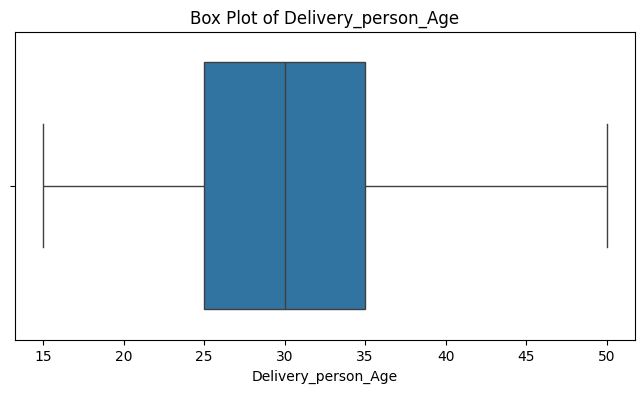

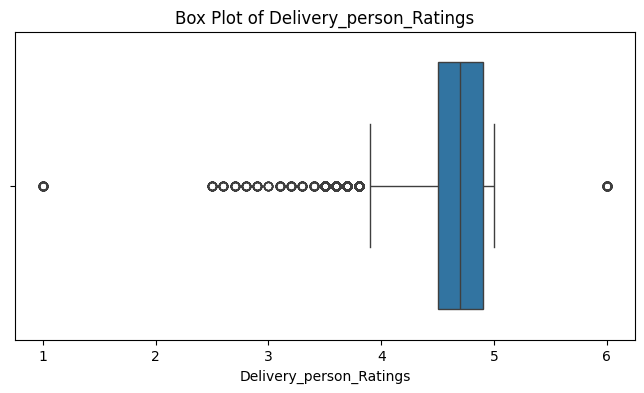

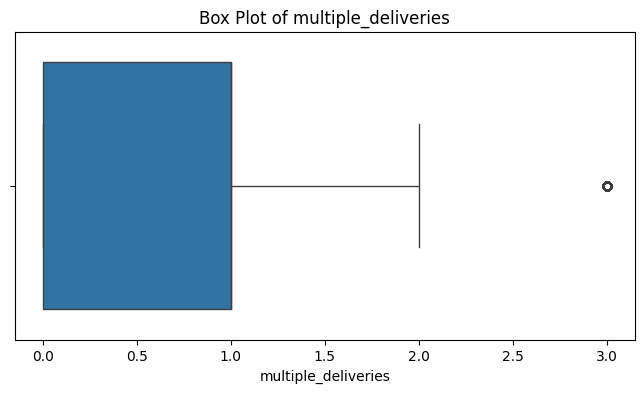

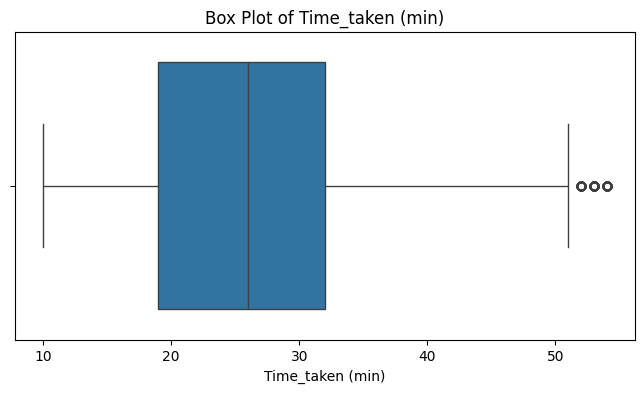

In [9]:
#box plot ji
import matplotlib.pyplot as plt
import seaborn as sns

for col in columns_to_check:
    plt.figure(figsize=(8, 4))
    sns.boxplot(x=df[col])
    plt.title("Box Plot of " + col)
    plt.xlabel(col)
    plt.show()


investigate the rating value of 6

In [10]:
print("Rating values:")
print(sorted(df['Delivery_person_Ratings'].dropna().unique()))

print("\nRecords with rating above 5:")
print(df[df['Delivery_person_Ratings'] > 5][
    ['Delivery_person_ID', 'Delivery_person_Ratings']
].head(10))

Rating values:
[np.float64(1.0), np.float64(2.5), np.float64(2.6), np.float64(2.7), np.float64(2.8), np.float64(2.9), np.float64(3.0), np.float64(3.1), np.float64(3.2), np.float64(3.3), np.float64(3.4), np.float64(3.5), np.float64(3.6), np.float64(3.7), np.float64(3.8), np.float64(3.9), np.float64(4.0), np.float64(4.1), np.float64(4.2), np.float64(4.3), np.float64(4.4), np.float64(4.5), np.float64(4.6), np.float64(4.7), np.float64(4.8), np.float64(4.9), np.float64(5.0), np.float64(6.0)]

Records with rating above 5:
     Delivery_person_ID  Delivery_person_Ratings
3577     BANGRES05DEL01                      6.0
4705      HYDRES17DEL01                      6.0
5160      JAPRES08DEL01                      6.0
5353     BANGRES19DEL01                      6.0
5642      AGRRES13DEL02                      6.0
6385      JAPRES06DEL02                      6.0
7022      MYSRES15DEL02                      6.0
7672      VADRES09DEL01                      6.0
9490    BANGRES010DEL01              

my observation : dataset contains ratings of 6.0, while all the other observed ratings are between 1.0 and 5.0.

In [11]:
#Step 1: Count how many records have a rating of 6
print("Number of ratings equal to 6:")
print((df['Delivery_person_Ratings'] == 6).sum())

print("\nPercentage of ratings equal to 6:")
print((df['Delivery_person_Ratings'] == 6).mean() * 100)

Number of ratings equal to 6:
53

Percentage of ratings equal to 6:
0.11626886626886626


check the age variable

In [12]:
print("Age values:")
print(sorted(df['Delivery_person_Age'].dropna().unique()))

print("\nRecords with age below 18:")
print(df[df['Delivery_person_Age'] < 18][
    ['Delivery_person_ID', 'Delivery_person_Age']
])

print("\nRecords with age above 45:")
print(df[df['Delivery_person_Age'] > 45][
    ['Delivery_person_ID', 'Delivery_person_Age']
])

Age values:
[np.float64(15.0), np.float64(20.0), np.float64(21.0), np.float64(22.0), np.float64(23.0), np.float64(24.0), np.float64(25.0), np.float64(26.0), np.float64(27.0), np.float64(28.0), np.float64(29.0), np.float64(30.0), np.float64(31.0), np.float64(32.0), np.float64(33.0), np.float64(34.0), np.float64(35.0), np.float64(36.0), np.float64(37.0), np.float64(38.0), np.float64(39.0), np.float64(50.0)]

Records with age below 18:
      Delivery_person_ID  Delivery_person_Age
2378       JAPRES15DEL03                 15.0
2896     INDORES010DEL03                 15.0
2942       SURRES17DEL03                 15.0
5893      CHENRES15DEL03                 15.0
9147      BANGRES05DEL01                 15.0
10891      MUMRES14DEL02                 15.0
11116      SURRES12DEL01                 15.0
12084     INDORES03DEL02                 15.0
15115   RANCHIRES02DEL01                 15.0
15918     CHENRES08DEL02                 15.0
16075      MUMRES02DEL01                 15.0
16453      

Age 15: 38 records. These need verification because they are unusually low for delivery personnel.

Age 50: 53 records. These are not automatically incorrect; age 50 can be a valid age.

Both values occur repeatedly, so we should investigate them rather than assume they are random errors.

In [13]:
print("Records with both age 50 and rating 6:")
print(
    df[
        (df['Delivery_person_Age'] == 50) &
        (df['Delivery_person_Ratings'] == 6)
    ][
        ['Delivery_person_ID', 'Delivery_person_Age',
         'Delivery_person_Ratings', 'Time_taken (min)']
    ]
)

print("\nCount:")
print(
    (
        (df['Delivery_person_Age'] == 50) &
        (df['Delivery_person_Ratings'] == 6)
    ).sum()
)

Records with both age 50 and rating 6:
      Delivery_person_ID  Delivery_person_Age  Delivery_person_Ratings  \
3577      BANGRES05DEL01                 50.0                      6.0   
4705       HYDRES17DEL01                 50.0                      6.0   
5160       JAPRES08DEL01                 50.0                      6.0   
5353      BANGRES19DEL01                 50.0                      6.0   
5642       AGRRES13DEL02                 50.0                      6.0   
6385       JAPRES06DEL02                 50.0                      6.0   
7022       MYSRES15DEL02                 50.0                      6.0   
7672       VADRES09DEL01                 50.0                      6.0   
9490     BANGRES010DEL01                 50.0                      6.0   
9526    RANCHIRES13DEL01                 50.0                      6.0   
10091      MYSRES04DEL01                 50.0                      6.0   
10728      DEHRES18DEL02                 50.0                      6.0   

Calculate outliers using IQR

In [14]:
columns_to_check = [
    'Delivery_person_Age',
    'Delivery_person_Ratings',
    'multiple_deliveries',
    'Time_taken (min)'
]

for col in columns_to_check:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)

    IQR = Q3 - Q1

    lower_limit = Q1 - 1.5 * IQR
    upper_limit = Q3 + 1.5 * IQR

    outliers = df[
        (df[col] < lower_limit) |
        (df[col] > upper_limit)
    ]

    print("\nVariable:", col)
    print("Lower limit:", lower_limit)
    print("Upper limit:", upper_limit)
    print("Number of outliers:", len(outliers))
    print("Percentage of outliers:", round(len(outliers) / df[col].notna().sum() * 100, 2), "%")


Variable: Delivery_person_Age
Lower limit: 10.0
Upper limit: 50.0
Number of outliers: 0
Percentage of outliers: 0.0 %

Variable: Delivery_person_Ratings
Lower limit: 3.8999999999999995
Upper limit: 5.500000000000001
Number of outliers: 1223
Percentage of outliers: 2.8 %

Variable: multiple_deliveries
Lower limit: -1.5
Upper limit: 2.5
Number of outliers: 361
Percentage of outliers: 0.81 %

Variable: Time_taken (min)
Lower limit: -0.5
Upper limit: 51.5
Number of outliers: 270
Percentage of outliers: 0.59 %


observation : The IQR method identified potential outliers in delivery-person ratings, multiple deliveries and delivery time. No IQR outliers were identified in delivery-person age. However, statistical outliers were not automatically treated as errors.

check missing values and duplicates again

In [15]:
data_quality = pd.DataFrame({
    'Missing Values': df.isnull().sum(),
    'Missing Percentage': (df.isnull().sum() / len(df)) * 100,
    'Data Type': df.dtypes
})

print(data_quality)
print("\nTotal duplicate rows:", df.duplicated().sum())

                             Missing Values  Missing Percentage Data Type
ID                                        0            0.000000    object
Delivery_person_ID                        0            0.000000    object
Delivery_person_Age                    1854            4.067217   float64
Delivery_person_Ratings                1908            4.185679   float64
Restaurant_latitude                       0            0.000000   float64
Restaurant_longitude                      0            0.000000   float64
Delivery_location_latitude                0            0.000000   float64
Delivery_location_longitude               0            0.000000   float64
Order_Date                                0            0.000000    object
Time_Orderd                            1731            3.797385    object
Time_Order_picked                         0            0.000000    object
Weather_conditions                      616            1.351351    object
Road_traffic_density                  

Examine missing values

In [16]:
columns_with_missing = df.columns[df.isnull().any()]

for col in columns_with_missing:
    print("\nVariable:", col)

    print("Missing records:", df[col].isnull().sum())

    print("Average delivery time when value is missing:")
    print(df.loc[df[col].isnull(), 'Time_taken (min)'].mean())

    print("Average delivery time when value is available:")
    print(df.loc[df[col].notnull(), 'Time_taken (min)'].mean())


Variable: Delivery_person_Age
Missing records: 1854
Average delivery time when value is missing:
26.464940668824163
Average delivery time when value is available:
26.28671392636634

Variable: Delivery_person_Ratings
Missing records: 1908
Average delivery time when value is missing:
26.42243186582809
Average delivery time when value is available:
26.288350581555086

Variable: Time_Orderd
Missing records: 1731
Average delivery time when value is missing:
26.31426920854997
Average delivery time when value is available:
26.293161243244477

Variable: Weather_conditions
Missing records: 616
Average delivery time when value is missing:
26.545454545454547
Average delivery time when value is available:
26.290517701476606

Variable: Road_traffic_density
Missing records: 601
Average delivery time when value is missing:
26.54242928452579
Average delivery time when value is available:
26.29064313184981

Variable: multiple_deliveries
Missing records: 993
Average delivery time when value is missing:

Create a cleaned copy and handle missing values

In [17]:
# Keep the original dataset unchanged
df_clean = df.copy()

# Numerical columns: median imputation + missing indicators
numeric_cols = [
    'Delivery_person_Age',
    'Delivery_person_Ratings',
    'multiple_deliveries'
]

for col in numeric_cols:
    df_clean[col + '_missing'] = df_clean[col].isnull().astype(int)
    df_clean[col] = df_clean[col].fillna(df_clean[col].median())

# Categorical columns: fill missing values as Unknown
categorical_cols = [
    'Time_Orderd',
    'Weather_conditions',
    'Road_traffic_density',
    'Festival',
    'City'
]

for col in categorical_cols:
    df_clean[col] = df_clean[col].fillna('Unknown')

# Verify missing values after treatment
print("Missing values after treatment:")
print(df_clean.isnull().sum()[df_clean.isnull().sum() > 0])

print("\nOriginal dataset shape:", df.shape)
print("Cleaned dataset shape:", df_clean.shape)

Missing values after treatment:
Series([], dtype: int64)

Original dataset shape: (45584, 20)
Cleaned dataset shape: (45584, 23)


Check geographical coordinates

In [18]:
coordinate_cols = [
    'Restaurant_latitude',
    'Restaurant_longitude',
    'Delivery_location_latitude',
    'Delivery_location_longitude'
]

print("Coordinate summary:")
print(df_clean[coordinate_cols].describe().T)

print("\nRecords with coordinates equal to 0.01:")
print(
    (df_clean[coordinate_cols] == 0.01).sum()
)

print("\nRecords with negative coordinates:")
print(
    (df_clean[coordinate_cols] < 0).sum()
)

print("\nSample records with suspicious coordinates:")
print(
    df_clean[
        (df_clean[coordinate_cols] == 0.01).any(axis=1) |
        (df_clean[coordinate_cols] < 0).any(axis=1)
    ][coordinate_cols].head(10)
)

Coordinate summary:
                               count       mean        std        min  \
Restaurant_latitude          45584.0  17.017948   8.185674 -30.905562   
Restaurant_longitude         45584.0  70.229684  22.885575 -88.366217   
Delivery_location_latitude   45584.0  17.465480   7.335562   0.010000   
Delivery_location_longitude  45584.0  70.844161  21.120578   0.010000   

                                   25%        50%        75%        max  
Restaurant_latitude          12.933284  18.551440  22.728163  30.914057  
Restaurant_longitude         73.170000  75.897963  78.044095  88.433452  
Delivery_location_latitude   12.988453  18.633934  22.785049  31.054057  
Delivery_location_longitude  73.280000  76.002574  78.107044  88.563452  

Records with coordinates equal to 0.01:
Restaurant_latitude              0
Restaurant_longitude             0
Delivery_location_latitude     327
Delivery_location_longitude    327
dtype: int64

Records with negative coordinates:
Restaurant_lat

observation:

The delivery coordinates contain 0.01 in both latitude and longitude for 327 records. These may be placeholder values rather than actual GPS locations.

Negative restaurant coordinates are suspicious because this dataset represents Indian delivery operations. The sample also contains restaurant coordinates of (0, 0), which need investigation.

Check exact zero and suspicious coordinate records

In [19]:
# Count exact zero values in each coordinate column
print("Exact zero values:")
print((df_clean[coordinate_cols] == 0).sum())

# Count records with at least one zero coordinate
zero_records = df_clean[
    (df_clean[coordinate_cols] == 0).any(axis=1)
]

print("\nRecords with at least one zero coordinate:")
print(len(zero_records))

# Count records with negative restaurant coordinates
negative_records = df_clean[
    (df_clean['Restaurant_latitude'] < 0) |
    (df_clean['Restaurant_longitude'] < 0)
]

print("\nRecords with negative restaurant coordinates:")
print(len(negative_records))

# Count records with delivery coordinates equal to 0.01
placeholder_records = df_clean[
    (df_clean['Delivery_location_latitude'] == 0.01) &
    (df_clean['Delivery_location_longitude'] == 0.01)
]

print("\nRecords with both delivery coordinates equal to 0.01:")
print(len(placeholder_records))

Exact zero values:
Restaurant_latitude            3640
Restaurant_longitude           3640
Delivery_location_latitude        0
Delivery_location_longitude       0
dtype: int64

Records with at least one zero coordinate:
3640

Records with negative restaurant coordinates:
431

Records with both delivery coordinates equal to 0.01:
327


Flag unreliable GPS records

In [20]:
# Create a flag for unreliable GPS coordinates
df_clean['invalid_gps'] = (
    (df_clean['Restaurant_latitude'] <= 0) |
    (df_clean['Restaurant_longitude'] <= 0) |
    (
        (df_clean['Delivery_location_latitude'] == 0.01) &
        (df_clean['Delivery_location_longitude'] == 0.01)
    )
).astype(int)

# Check the combined count
print("Records with unreliable GPS coordinates:")
print(df_clean['invalid_gps'].sum())

print("\nRecords with valid GPS coordinates:")
print((df_clean['invalid_gps'] == 0).sum())

print("\nFlag distribution:")
print(df_clean['invalid_gps'].value_counts())

Records with unreliable GPS coordinates:
4071

Records with valid GPS coordinates:
41513

Flag distribution:
invalid_gps
0    41513
1     4071
Name: count, dtype: int64


In [21]:
#Calculate delivery distance in kilometres
# Create a valid GPS mask
valid_gps = df_clean['invalid_gps'] == 0

# Convert latitude and longitude into radians
lat1 = np.radians(df_clean['Restaurant_latitude'])
lon1 = np.radians(df_clean['Restaurant_longitude'])

lat2 = np.radians(df_clean['Delivery_location_latitude'])
lon2 = np.radians(df_clean['Delivery_location_longitude'])

# Calculate differences
dlat = lat2 - lat1
dlon = lon2 - lon1

# Haversine formula
a = (
    np.sin(dlat / 2) ** 2 +
    np.cos(lat1) * np.cos(lat2) *
    np.sin(dlon / 2) ** 2
)

c = 2 * np.arcsin(np.sqrt(a))

# Distance in kilometres
df_clean['distance_km'] = np.where(
    valid_gps,
    6371 * c,
    np.nan
)

# Check the result
print("Distance summary:")
print(df_clean['distance_km'].describe())

print("\nMissing distance values:")
print(df_clean['distance_km'].isnull().sum())

print("\nSample calculated distances:")
print(df_clean[['distance_km', 'Time_taken (min)']].head(10))

Distance summary:
count    41513.000000
mean         9.719824
std          5.602505
min          1.465067
25%          4.657655
50%          9.193021
75%         13.680920
max         20.969489
Name: distance_km, dtype: float64

Missing distance values:
4071

Sample calculated distances:
   distance_km  Time_taken (min)
0    10.280582                46
1     6.242319                23
2    13.787860                21
3     2.930258                20
4    19.396618                41
5    13.763977                20
6     6.218001                33
7    16.849940                40
8    10.757109                41
9     4.540574                15


Visualise delivery distance

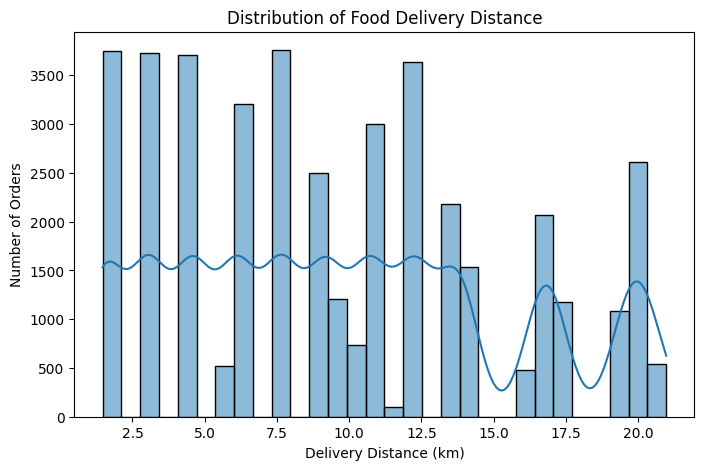

In [22]:
# Histogram of delivery distance
plt.figure(figsize=(8, 5))

sns.histplot(
    df_clean['distance_km'].dropna(),
    bins=30,
    kde=True
)

plt.title('Distribution of Food Delivery Distance')
plt.xlabel('Delivery Distance (km)')
plt.ylabel('Number of Orders')

plt.show()

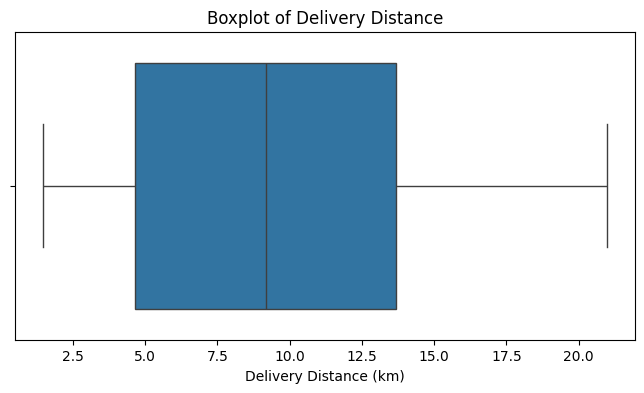

In [23]:
# Boxplot of delivery distance
plt.figure(figsize=(8, 4))

sns.boxplot(x=df_clean['distance_km'])

plt.title('Boxplot of Delivery Distance')
plt.xlabel('Delivery Distance (km)')

plt.show()


Analyse the relationship between delivery distance and delivery time

Correlation between distance and delivery time: 0.3210619560247977


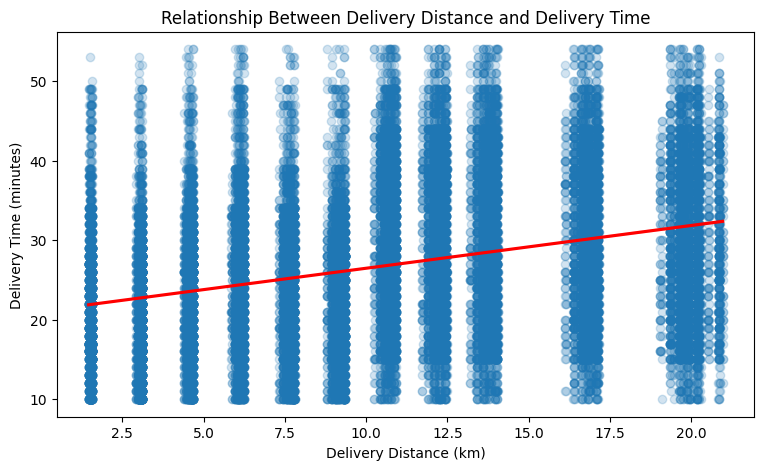

In [24]:
# Select rows where both distance and delivery time are available
distance_time = df_clean[
    ['distance_km', 'Time_taken (min)']
].dropna()

# Calculate correlation
correlation = distance_time['distance_km'].corr(
    distance_time['Time_taken (min)']
)

print("Correlation between distance and delivery time:", correlation)

# Create scatter plot with a trend line
plt.figure(figsize=(9, 5))

sns.regplot(
    data=distance_time,
    x='distance_km',
    y='Time_taken (min)',
    scatter_kws={'alpha': 0.2},
    line_kws={'color': 'red'}
)

plt.title('Relationship Between Delivery Distance and Delivery Time')
plt.xlabel('Delivery Distance (km)')
plt.ylabel('Delivery Time (minutes)')
plt.show()